<a href="https://colab.research.google.com/github/venkatasai-eng/Computer-Vision/blob/main/Exp_27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving human faces.jpg to human faces (8).jpg


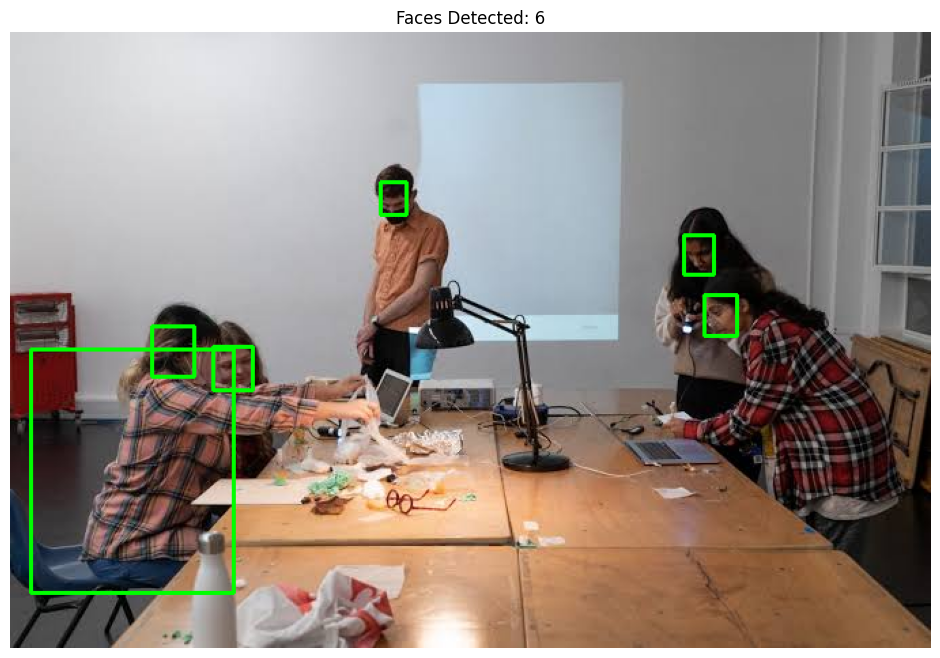

Total faces detected: 6


In [12]:
!pip install -q --upgrade opencv-python-headless

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from google.colab import files

url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
urllib.request.urlretrieve(url, "face_detection.onnx")
uploaded = files.upload()
img = cv2.imread(next(iter(uploaded)))

if img is None:
    raise ValueError("Unable to read image")

h, w = img.shape[:2]
detector = cv2.FaceDetectorYN.create(
    "face_detection.onnx", "", (w, h),
    0.4, 0.3, 5000
)

_, faces = detector.detect(img)

count = 0

if faces is not None:
    for face in faces:
        x, y, fw, fh = map(int, face[:4])
        cv2.rectangle(img, (x, y), (x + fw, y + fh),
                      (0, 255, 0), 2)
        count += 1

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Faces Detected: {count}")
plt.axis("off")
plt.show()

print("Total faces detected:", count)